# Problem 5 · Steady convection and diffusion in one dimension

**simple_CFD · Introduction to Computational Fluid Dynamics with the Finite Difference Method**

> *A property $\phi$ (for example a temperature or a concentration) is carried by a flow with constant velocity $u$ from one reservoir, where $\phi = 1$, to another, where $\phi = 0$, while it also diffuses. Find the steady distribution of $\phi$ with the Finite Difference Method, for a slow flow ($u = 0.1$ m/s) and a fast flow ($u = 2.5$ m/s), using central and upwind differences for the convection term.*

*(Adapted from Versteeg & Malalasekera, An Introduction to Computational Fluid Dynamics, chapter 5.)*

In this notebook we solve the problem **step by step, following the 7 pillars of CFD**:

| Pillar | What we do here |
|:-:|---|
| 1 · Geometry | describe the domain between the two reservoirs and collect the data |
| 2 · Grid | divide it into 5 intervals and compute the cell Péclet number |
| 3 · Physics | write the convection–diffusion equation and its exact solution |
| 4 · Numerical scheme | two ways to discretize the convection term: central (CDS) and upwind (UDS) |
| 5 · Solution setup | solve the tridiagonal system with the Thomas algorithm |
| 6 · Compute | run both schemes for the slow and the fast flow |
| 7 · Post-processing | explain the wiggles, measure the false diffusion, refine the grid, test Gauss–Seidel |

> **Plain Python only.** All numerical work uses ordinary Python lists and `for` loops, so you can follow every number. The only import used in the calculations is `math` (part of Python itself), for `exp` in the exact solution and `log` in the order of accuracy. The figures are drawn by `plots.py` (with matplotlib); you do not need to open it to follow the method.

In [1]:
import math     # built into Python: exp, log
import plots    # our drawing helpers (plots.py)

---
## Pillar 1 · The physical problem and its geometry

Problems 1 to 4 were about heat **diffusing** through a solid. A solid does not move, so heat could only spread out. In a **fluid**, the material itself moves and **carries** heat, dye or pollution along with it. This transport by the flow is called **convection** (or *advection*). It is what makes CFD *fluid* dynamics: every equation of fluid flow, including the Navier–Stokes equations, contains a convection term.

Here a fluid flows with a constant velocity $u$ through a straight channel of length $L$, from a reservoir on the left, where $\phi = 1$, to a reservoir on the right, where $\phi = 0$. Two things move $\phi$ along the channel:

* **convection**: the flow carries $\phi$ downstream, from left to right;
* **diffusion**: $\phi$ spreads from high to low values, in both directions.

| Quantity | Symbol | Value |
|---|:-:|---|
| length of the domain | $L$ | 1.0 m |
| density | $\rho$ | 1.0 kg/m³ |
| diffusion coefficient | $\Gamma$ | 0.1 kg/(m·s) |
| value at the left end (inlet reservoir) | $\phi_0$ | 1 |
| value at the right end (outlet reservoir) | $\phi_L$ | 0 |
| velocity, case 1 (slow flow) | $u$ | 0.1 m/s |
| velocity, case 2 (fast flow) | $u$ | 2.5 m/s |

**Assumptions:** steady state, one-dimensional flow, constant $\rho$, $\Gamma$ and $u$, no source of $\phi$.

In [2]:
# ---- domain and fluid ----------------------------------------------------
L = 1.0           # length of the domain               [m]
rho = 1.0         # density                            [kg/m^3]
Gamma = 0.1       # diffusion coefficient              [kg/(m s)]

# ---- boundary conditions -------------------------------------------------
phi_0 = 1.0       # phi at x = 0 (left reservoir)
phi_L = 0.0       # phi at x = L (right reservoir)

# ---- the two flow velocities ---------------------------------------------
u_slow = 0.1      # case 1                             [m/s]
u_fast = 2.5      # case 2                             [m/s]

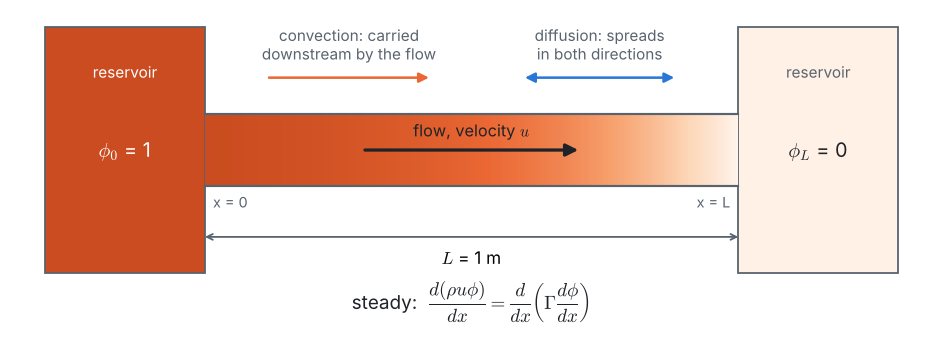

In [3]:
plots.schematic(L, phi_0, phi_L)

Which of the two effects wins? Compare the strength of convection, $\rho u$, with the strength of diffusion over the length of the domain, $\Gamma/L$. Their ratio is the **Péclet number**:

$$Pe_L = \frac{\text{convection}}{\text{diffusion}} = \frac{\rho\,u\,L}{\Gamma}.$$

A small $Pe_L$ means diffusion dominates; a large $Pe_L$ means the flow sweeps $\phi$ downstream faster than it can diffuse back.

In [4]:
for u in (u_slow, u_fast):
    print(f"u = {u:3.1f} m/s:   Pe_L = rho u L / Gamma = {rho * u * L / Gamma:4.1f}")

u = 0.1 m/s:   Pe_L = rho u L / Gamma =  1.0
u = 2.5 m/s:   Pe_L = rho u L / Gamma = 25.0


---
## Pillar 2 · The grid

As in Problem 1, we keep $N+1$ equally spaced nodes,

$$x_i = i\,\Delta x, \qquad i = 0, 1, \dots, N, \qquad \Delta x = \frac{L}{N}.$$

Nodes $0$ and $N$ sit in the two reservoirs, so their values are known. We start with a deliberately **coarse** grid, $N = 5$: nodes $1$ to $4$ are the **four unknowns**, small enough to solve by hand on the board.

In [5]:
N = 5                     # number of intervals
dx = L / N                # grid spacing [m]

x = []                    # list with the position of every node
for i in range(N + 1):
    x.append(i * dx)

print(f"N = {N} intervals, dx = {dx:.1f} m, {len(x)} nodes")
print("node positions [m]:", [round(xi, 2) for xi in x])

N = 5 intervals, dx = 0.2 m, 6 nodes
node positions [m]: [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]


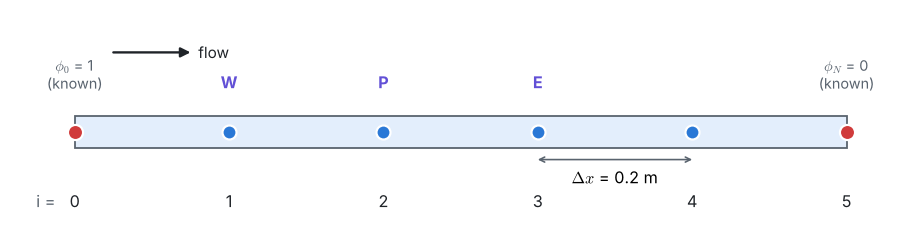

In [6]:
plots.grid(x)

The grid brings a second Péclet number, measured over **one grid interval** instead of the whole domain. This **cell Péclet number** will decide whether our scheme works:

$$Pe_\Delta = \frac{\rho\,u\,\Delta x}{\Gamma}.$$

In [7]:
for u in (u_slow, u_fast):
    print(f"u = {u:3.1f} m/s:   cell Peclet number Pe = rho u dx / Gamma = {rho * u * dx / Gamma:3.1f}")

u = 0.1 m/s:   cell Peclet number Pe = rho u dx / Gamma = 0.2
u = 2.5 m/s:   cell Peclet number Pe = rho u dx / Gamma = 5.0


---
## Pillar 3 · Physics: the convection–diffusion equation

Take a thin slice of the channel between $x$ and $x + dx$ and balance the **flux** of $\phi$ through its two faces. Two fluxes cross each face:

* the **convective flux** $\rho u\,\phi$: the flow carries $\phi$ with it;
* the **diffusive flux** $-\Gamma\,d\phi/dx$: $\phi$ spreads from high to low values (Fick's or Fourier's law).

In steady state with no source, what flows in must flow out, so the total flux is the same everywhere: $\dfrac{d}{dx}\left(\rho u\,\phi - \Gamma\,\dfrac{d\phi}{dx}\right) = 0$, i.e.

$$\underbrace{\frac{d(\rho u\,\phi)}{dx}}_{\text{convection}} \;=\; \underbrace{\frac{d}{dx}\!\left(\Gamma\,\frac{d\phi}{dx}\right)}_{\text{diffusion}},
\qquad \phi(0) = \phi_0, \qquad \phi(L) = \phi_L.$$

This is the steady, one-dimensional version of the **generic transport equation** on the course home page. The flow must also conserve mass: in 1D, the **continuity equation** is $d(\rho u)/dx = 0$, so $\rho u$ is the same everywhere. With constant $\Gamma$ the equation becomes $\rho u\,\phi' = \Gamma\,\phi''$.

The two terms behave very differently:

* **diffusion** spreads $\phi$ in **both** directions: a change at one point is felt upstream and downstream;
* **convection** carries $\phi$ in **one** direction only, the direction of the flow. This is called **transportiveness**: the value at a point is mostly decided by what comes from *upstream*.

The equation has an **exact solution**, which we will use to judge every numerical result:

$$\frac{\phi(x) - \phi_0}{\phi_L - \phi_0} = \frac{\exp(\rho u x/\Gamma) - 1}{\exp(\rho u L/\Gamma) - 1}.$$

Because $\phi_0 = 1$ and $\phi_L = 0$, the exact solution can never leave the range $0 \le \phi \le 1$: there is no source, so $\phi$ cannot be larger than the largest boundary value or smaller than the smallest one. A good numerical scheme should keep this property, called **boundedness**.

In [8]:
def phi_exact(xx, u):
    """Exact solution at position xx [m] for velocity u [m/s]."""
    Pe_L = rho * u * L / Gamma
    return phi_0 + (phi_L - phi_0) * (math.exp(Pe_L * xx / L) - 1) / (math.exp(Pe_L) - 1)


for u in (u_slow, u_fast):
    print(f"u = {u:3.1f} m/s:  exact phi at the nodes =", [round(phi_exact(xi, u), 4) for xi in x])

u = 0.1 m/s:  exact phi at the nodes = [1.0, 0.8711, 0.7138, 0.5215, 0.2868, 0.0]
u = 2.5 m/s:  exact phi at the nodes = [1.0, 1.0, 1.0, 1.0, 0.9933, 0.0]


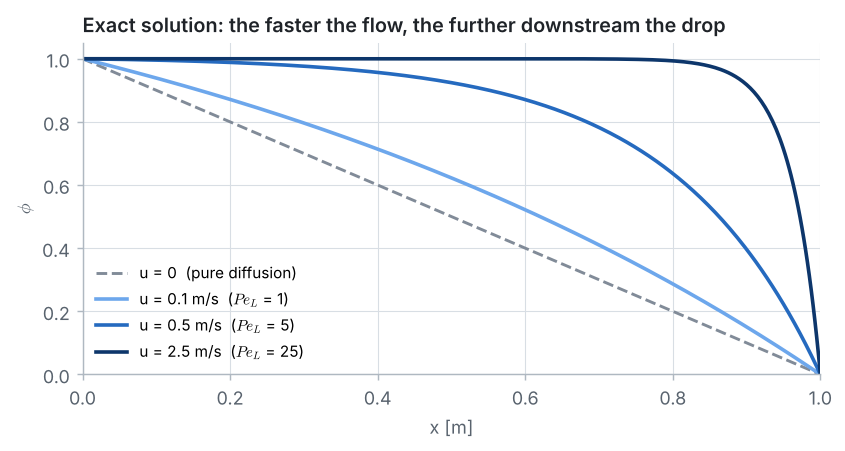

In [9]:
plots.exact_family(L, phi_exact, rho, Gamma)

Without flow ($u = 0$) we get the straight line of pure diffusion. The faster the flow, the further downstream the profile is pushed: at $u = 2.5$ m/s, $\phi$ stays close to 1 almost to the end and then drops to 0 in a thin **boundary layer** in front of the outlet. Its thickness is about $\Gamma/(\rho u) = 0.04$ m, smaller than one grid interval of our coarse grid ($\Delta x = 0.2$ m). That will be the challenge.

---
## Pillar 4 · Numerical scheme: from the differential equation to algebraic equations

At an interior node $i$ (we also call it $P$, with west neighbour $W = i-1$ and east neighbour $E = i+1$) we need finite differences for **two** derivatives.

**Diffusion term.** As in Problem 1, the central difference (2nd order):

$$\Gamma\,\frac{d^2\phi}{dx^2}\bigg|_i \approx \Gamma\,\frac{\phi_{i-1} - 2\phi_i + \phi_{i+1}}{\Delta x^2}.$$

**Convection term, scheme A: central differences (CDS).** The obvious choice, also 2nd order:

$$\rho u\,\frac{d\phi}{dx}\bigg|_i \approx \rho u\,\frac{\phi_{i+1} - \phi_{i-1}}{2\,\Delta x}.$$

**Convection term, scheme B: upwind differences (UDS).** Use only the node the flow comes **from**. For $u > 0$ that is the west node, so we take the backward difference (only 1st order):

$$\rho u\,\frac{d\phi}{dx}\bigg|_i \approx \rho u\,\frac{\phi_i - \phi_{i-1}}{\Delta x}.$$

Multiply everything by $\Delta x$ and use the two **flux strengths**

$$F = \rho u \quad\text{(convection)}, \qquad D = \frac{\Gamma}{\Delta x} \quad\text{(diffusion)}, \qquad \frac{F}{D} = Pe_\Delta.$$

Both schemes give an equation of the same shape:

$$a_P\,\phi_i = a_W\,\phi_{i-1} + a_E\,\phi_{i+1}, \qquad a_P = a_W + a_E,$$

with the **neighbour coefficients**

| | $a_W$ (west) | $a_E$ (east) | $a_P$ |
|---|:-:|:-:|:-:|
| central (CDS) | $D + F/2$ | $D - F/2$ | $2D$ |
| upwind (UDS), $u > 0$ | $D + F$ | $D$ | $2D + F$ |

Because $a_P = a_W + a_E$, each node value is a **weighted average** of its two neighbours, with weights $a_W/a_P$ and $a_E/a_P$, provided both weights are positive. Look at the CDS east coefficient: $a_E = D - F/2$ becomes **negative** as soon as $F > 2D$, i.e. $Pe_\Delta > 2$. Let us compute the coefficients for our two flows:

In [10]:
def coefficients(u, N, scheme):
    """Neighbour coefficients a_W, a_E, a_P of an interior node."""
    F = rho * u               # convective flux strength [kg/(m^2 s)]
    D = Gamma / (L / N)       # diffusive flux strength  [kg/(m^2 s)]
    if scheme == "CDS":
        a_W = D + F / 2
        a_E = D - F / 2
    else:                     # "UDS", for a flow from left to right (u > 0)
        a_W = D + F
        a_E = D
    return a_W, a_E, a_W + a_E

In [11]:
print("  u [m/s]  scheme    a_W     a_E     a_P    |a_W|+|a_E| <= a_P ?")
for u in (u_slow, u_fast):
    for scheme in ("CDS", "UDS"):
        a_W, a_E, a_P = coefficients(u, N, scheme)
        dominant = "yes" if abs(a_W) + abs(a_E) <= a_P + 1e-12 else "NO"
        print(f"   {u:4.1f}    {scheme}   {a_W:6.3f}  {a_E:6.3f}  {a_P:6.3f}        {dominant}")

  u [m/s]  scheme    a_W     a_E     a_P    |a_W|+|a_E| <= a_P ?
    0.1    CDS    0.550   0.450   1.000        yes
    0.1    UDS    0.600   0.500   1.100        yes
    2.5    CDS    1.750  -0.750   1.000        NO
    2.5    UDS    3.000   0.500   3.500        yes


The last column checks **diagonal dominance**: the centre coefficient must be at least as large as the sum of the sizes of the neighbour coefficients. For $u = 2.5$ m/s ($Pe_\Delta = 5$), CDS gives a **negative** east coefficient and loses diagonal dominance. Upwind keeps all coefficients positive for *any* velocity.

As in Problem 1, we write every equation as $a_i\,\phi_{i-1} + b_i\,\phi_i + c_i\,\phi_{i+1} = r_i$ and store the four lists of a **tridiagonal** system. The two boundary nodes simply say $\phi_0 = 1$ and $\phi_N = 0$.

In [12]:
def build_system(u, N, scheme):
    """Coefficients a, b, c, r of the FDM equations for N intervals."""
    a_W, a_E, a_P = coefficients(u, N, scheme)

    a = [0.0] * (N + 1)   # coefficient of phi[i-1]
    b = [0.0] * (N + 1)   # coefficient of phi[i]
    c = [0.0] * (N + 1)   # coefficient of phi[i+1]
    r = [0.0] * (N + 1)   # right-hand side

    # node 0, left reservoir: phi[0] = phi_0
    b[0] = 1.0
    r[0] = phi_0

    # interior nodes: -a_W phi[i-1] + a_P phi[i] - a_E phi[i+1] = 0
    for i in range(1, N):
        a[i] = -a_W
        b[i] = a_P
        c[i] = -a_E

    # node N, right reservoir: phi[N] = phi_L
    b[N] = 1.0
    r[N] = phi_L

    return a, b, c, r

Here are the equations of the fast flow with CDS, exactly as you would write them by hand:

In [13]:
a, b, c, r = build_system(u_fast, N, "CDS")
for i in range(N + 1):
    terms = []
    if a[i] != 0:
        terms.append(f"{a[i]:+.2f}·phi{i - 1}")
    terms.append(f"{b[i]:+.2f}·phi{i}")
    if c[i] != 0:
        terms.append(f"{c[i]:+.2f}·phi{i + 1}")
    print(f"node {i}:  {'  '.join(terms):34s} = {r[i]:4.1f}")

node 0:  +1.00·phi0                         =  1.0
node 1:  -1.75·phi0  +1.00·phi1  +0.75·phi2 =  0.0
node 2:  -1.75·phi1  +1.00·phi2  +0.75·phi3 =  0.0
node 3:  -1.75·phi2  +1.00·phi3  +0.75·phi4 =  0.0
node 4:  -1.75·phi3  +1.00·phi4  +0.75·phi5 =  0.0
node 5:  +1.00·phi5                         =  0.0


---
## Pillar 5 · Solution setup: the Thomas algorithm

The system is tridiagonal, so we solve it **directly** with the **Thomas algorithm**, the same function as in Problem 1: a forward sweep removes $\phi_{i-1}$ from every equation, then back substitution gives the values from the right end back to the left end. It is exact (up to round-off) and does not care about the signs of the coefficients here, so it gives us the *true* answer of each scheme's equations. Any strange result we see must then come from the **scheme**, not from the solver.

(In Problem 1 we also used Gauss–Seidel iteration. Iterative solvers *do* care about the signs of the coefficients: we test this at the end of Pillar 7.)

In [14]:
def thomas(a, b, c, r):
    """Solve a tridiagonal system directly (Thomas algorithm)."""
    n = len(b)
    c_star = [0.0] * n
    r_star = [0.0] * n

    # forward sweep: remove phi[i-1] from every equation
    c_star[0] = c[0] / b[0]
    r_star[0] = r[0] / b[0]
    for i in range(1, n):
        denominator = b[i] - a[i] * c_star[i - 1]
        c_star[i] = c[i] / denominator
        r_star[i] = (r[i] - a[i] * r_star[i - 1]) / denominator

    # back substitution: from the right end back to the left end
    phi = [0.0] * n
    phi[n - 1] = r_star[n - 1]
    for i in range(n - 2, -1, -1):
        phi[i] = r_star[i] - c_star[i] * phi[i + 1]

    return phi


def solve(u, N, scheme):
    """Build and solve the FDM equations: phi at the N+1 nodes."""
    return thomas(*build_system(u, N, scheme))

---
## Pillar 6 · Compute

### Case 1 · slow flow, $u = 0.1$ m/s ($Pe_\Delta = 0.2$)

In [15]:
def compare(u, N):
    """Print CDS, UDS and the exact solution node by node."""
    phi_cds = solve(u, N, "CDS")
    phi_uds = solve(u, N, "UDS")
    print(" node   x [m]     CDS       UDS      exact    error CDS  error UDS")
    for i in range(N + 1):
        exact = phi_exact(x[i], u)
        print(f"{i:4d}    {x[i]:4.1f}   {phi_cds[i]:8.4f}  {phi_uds[i]:8.4f}  {exact:8.4f}"
              f"   {phi_cds[i] - exact:+8.4f}   {phi_uds[i] - exact:+8.4f}")
    return phi_cds, phi_uds

In [16]:
phi_cds_slow, phi_uds_slow = compare(u_slow, N)

 node   x [m]     CDS       UDS      exact    error CDS  error UDS
   0     0.0     1.0000    1.0000    1.0000    +0.0000    +0.0000
   1     0.2     0.8714    0.8656    0.8711    +0.0002    -0.0055
   2     0.4     0.7141    0.7044    0.7138    +0.0004    -0.0094
   3     0.6     0.5220    0.5109    0.5215    +0.0004    -0.0107
   4     0.8     0.2871    0.2786    0.2868    +0.0003    -0.0081
   5     1.0     0.0000    0.0000    0.0000    +0.0000    +0.0000


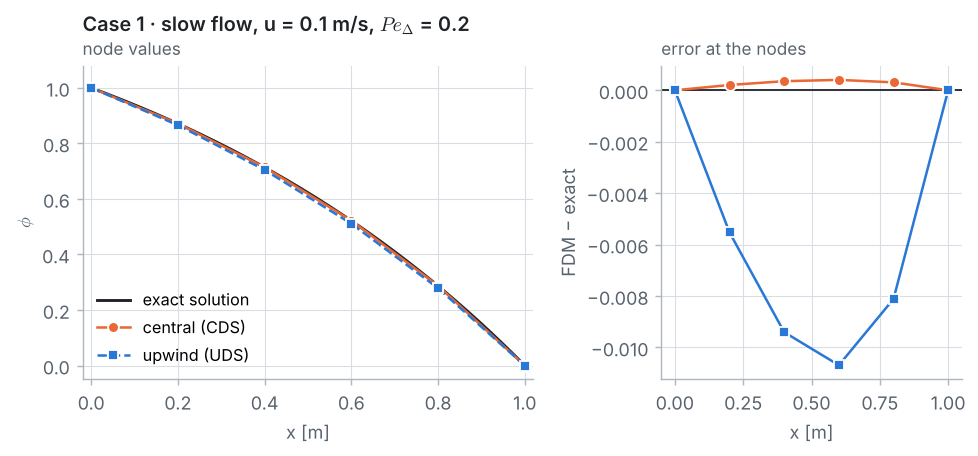

In [17]:
plots.profiles(x, phi_cds_slow, phi_uds_slow, lambda xx: phi_exact(xx, u_slow),
               f"Case 1 · slow flow, u = {u_slow} m/s, $Pe_\\Delta$ = {rho * u_slow * dx / Gamma:.1f}",
               show_error=True)

With a slow flow, diffusion dominates and both schemes work. The largest CDS error is only 0.0004; UDS is less accurate (largest error 0.011) but still close.

### Case 2 · fast flow, $u = 2.5$ m/s ($Pe_\Delta = 5$)

In [18]:
phi_cds_fast, phi_uds_fast = compare(u_fast, N)

 node   x [m]     CDS       UDS      exact    error CDS  error UDS
   0     0.0     1.0000    1.0000    1.0000    +0.0000    +0.0000
   1     0.2     0.9525    0.9994    1.0000    -0.0475    -0.0006
   2     0.4     1.0633    0.9955    1.0000    +0.0633    -0.0045
   3     0.6     0.8047    0.9723    1.0000    -0.1953    -0.0276
   4     0.8     1.4082    0.8334    0.9933    +0.4149    -0.1598
   5     1.0     0.0000    0.0000    0.0000    +0.0000    +0.0000


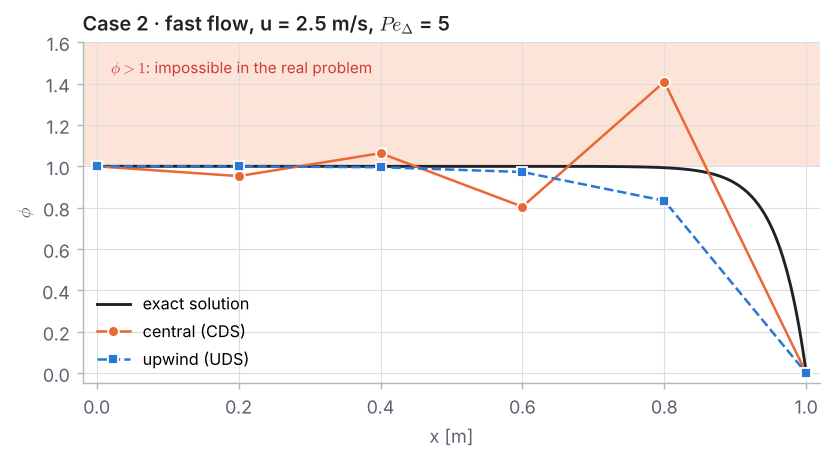

In [19]:
plots.profiles(x, phi_cds_fast, phi_uds_fast, lambda xx: phi_exact(xx, u_fast),
               f"Case 2 · fast flow, u = {u_fast} m/s, $Pe_\\Delta$ = {rho * u_fast * dx / Gamma:.0f}",
               bounds=True)

Now the two schemes behave completely differently:

* **CDS wiggles.** The values go down, up, down, up: 0.95, 1.06, 0.80, 1.41. Two of them are **larger than 1**, although no value of $\phi$ larger than 1 exists anywhere in the problem. The solution is *unbounded* and physically meaningless, At node 4 CDS gives 1.41, where the exact value is 0.99.
* **UDS is smooth and bounded.** All values lie between 0 and 1 and fall monotonically, like the exact solution. But the drop to 0 is **smeared**: at node 4 UDS gives 0.83 instead of 0.99.

Note that the Thomas algorithm solved the CDS equations *exactly*: the wiggles are the true answer of the CDS equations on this grid. The solver is fine; the scheme is not.

### Checking the whiteboard numbers

The whiteboard guide solves both cases by hand with the Thomas algorithm, writing every unknown in terms of the next one, $\phi_i = P_i\,\phi_{i+1} + Q_i$. These are exactly the numbers `thomas` computes in its forward sweep: $P_i = -$`c_star[i]` and $Q_i = $ `r_star[i]`. On the board all coefficients are divided by $D$ to get simpler numbers (this changes nothing in $P_i$, $Q_i$ or $\phi_i$). Here they are, to check the class's calculator results:

In [20]:
for u, scheme in ((u_slow, "CDS"), (u_fast, "CDS"), (u_fast, "UDS")):
    a_W, a_E, a_P = [coef / (Gamma / dx) for coef in coefficients(u, N, scheme)]   # divide by D
    print(f"u = {u} m/s, {scheme}:  a_W = {a_W:.2f}, a_P = {a_P:.2f}, a_E = {a_E:.2f}  (divided by D)")
    P, Q = 0.0, phi_0                     # node 0: phi_0 = 0 * phi_1 + phi_0
    for i in range(1, N):
        denominator = a_P - a_W * P
        P, Q = a_E / denominator, a_W * Q / denominator
        print(f"   i = {i}:  a_P - a_W P = {denominator:8.6f}   P = {P:+.6f}   Q = {Q:.6f}")

u = 0.1 m/s, CDS:  a_W = 1.10, a_P = 2.00, a_E = 0.90  (divided by D)
   i = 1:  a_P - a_W P = 2.000000   P = +0.450000   Q = 0.550000
   i = 2:  a_P - a_W P = 1.505000   P = +0.598007   Q = 0.401993
   i = 3:  a_P - a_W P = 1.342193   P = +0.670545   Q = 0.329455
   i = 4:  a_P - a_W P = 1.262401   P = +0.712927   Q = 0.287073
u = 2.5 m/s, CDS:  a_W = 3.50, a_P = 2.00, a_E = -1.50  (divided by D)
   i = 1:  a_P - a_W P = 2.000000   P = -0.750000   Q = 1.750000
   i = 2:  a_P - a_W P = 4.625000   P = -0.324324   Q = 1.324324
   i = 3:  a_P - a_W P = 3.135135   P = -0.478448   Q = 1.478448
   i = 4:  a_P - a_W P = 3.674569   P = -0.408211   Q = 1.408211
u = 2.5 m/s, UDS:  a_W = 6.00, a_P = 7.00, a_E = 1.00  (divided by D)
   i = 1:  a_P - a_W P = 7.000000   P = +0.142857   Q = 0.857143
   i = 2:  a_P - a_W P = 6.142857   P = +0.162791   Q = 0.837209
   i = 3:  a_P - a_W P = 6.023256   P = +0.166023   Q = 0.833977
   i = 4:  a_P - a_W P = 6.003861   P = +0.166559   Q = 0.833441


---
## Pillar 7 · Post-processing: why does CDS wiggle, and what does UDS cost?

### Why CDS wiggles: negative coefficients

Write the interior equation as a weighted average,

$$\phi_i = \frac{a_W}{a_P}\,\phi_{i-1} + \frac{a_E}{a_P}\,\phi_{i+1}.$$

If both weights are positive, every node value lies **between** its two neighbours, so no value can ever leave the range set by the boundaries: the scheme is **bounded**. With CDS at $Pe_\Delta = 5$ the weights are $a_W/a_P = 1.75$ and $a_E/a_P = -0.75$. A larger value downstream now *lowers* $\phi_i$, and the averaging property is lost.

The equations even tell us the shape of the answer. Try $\phi_i = s^i$ in $a_P\,\phi_i = a_W\,\phi_{i-1} + a_E\,\phi_{i+1}$: it works for $s = 1$ and for

$$s = \frac{a_W}{a_E} = \frac{1 + Pe_\Delta/2}{1 - Pe_\Delta/2} \;\;\text{(CDS)}, \qquad s = 1 + Pe_\Delta \;\;\text{(UDS)},$$

so every solution has the form $\phi_i = A + B\,s^i$. Fitting $A$ and $B$ to $\phi_0 = 1$ and $\phi_N = 0$ gives

$$\phi_i = 1 - \frac{s^i - 1}{s^N - 1}.$$

Compare with the exact solution at the nodes: since $\rho u\,x_i/\Gamma = i\,Pe_\Delta$, it is the same formula with $s$ replaced by $e^{Pe_\Delta}$. **A scheme is good when its $s$ is close to $e^{Pe_\Delta}$.** If $s$ is **negative**, $s^i$ changes sign from one node to the next: a zig-zag.

In [21]:
for u in (u_slow, u_fast):
    Pe = rho * u * dx / Gamma
    print(f"Pe = {Pe:3.1f}:   exact e^Pe = {math.exp(Pe):7.3f}    CDS s = {(1 + Pe / 2) / (1 - Pe / 2):+7.3f}"
          f"    UDS s = {1 + Pe:+7.3f}")

Pe = 0.2:   exact e^Pe =   1.221    CDS s =  +1.222    UDS s =  +1.200
Pe = 5.0:   exact e^Pe = 148.413    CDS s =  -2.333    UDS s =  +6.000


For $Pe_\Delta = 0.2$ both schemes have $s$ close to $e^{0.2} = 1.221$, CDS much closer (1.222) than UDS (1.200): that is why CDS was more accurate in case 1. For $Pe_\Delta = 5$ the exact factor is $e^5 = 148$. CDS has $s = -2.33$: every step flips the sign of the $B\,s^i$ part, and its size grows by 2.33 per node, which is exactly the zig-zag we saw. Upwind has $s = 6$, far too small, which is the smearing, but positive. Upwind always has $s = 1 + Pe_\Delta > 0$, so it **can never wiggle**, however fast the flow.

> **Rule of thumb: central differences for convection stay bounded only if $Pe_\Delta \le 2$.** Then $a_E = D - F/2 \ge 0$, both weights are positive and the matrix is diagonally dominant.

### What UDS costs: false diffusion

Upwinding is bounded, but its profile was smeared. Why? Rewrite the backward difference as a central difference plus a correction:

$$\frac{\phi_i - \phi_{i-1}}{\Delta x} = \frac{\phi_{i+1} - \phi_{i-1}}{2\Delta x} - \frac{\Delta x}{2}\,\frac{\phi_{i+1} - 2\phi_i + \phi_{i-1}}{\Delta x^2}.$$

So the upwind equations are **exactly** the central-difference equations with a larger diffusion coefficient,

$$\Gamma_{UDS} = \Gamma + \Gamma_{false}, \qquad \Gamma_{false} = \frac{\rho u\,\Delta x}{2}.$$

The extra, artificial part is called **false** (or **numerical**) **diffusion**. It is what keeps upwind bounded: with $\Gamma_{UDS}$ the cell Péclet number is always below 2. But it also smears the solution, as if the fluid diffused much more than it really does.

In [22]:
for u in (u_slow, u_fast):
    Gamma_false = rho * u * dx / 2
    print(f"u = {u:3.1f} m/s:  false diffusion = {Gamma_false:.3f} kg/(m s)  "
          f"= {Gamma_false / Gamma:4.2f} x the real Gamma")

u = 0.1 m/s:  false diffusion = 0.010 kg/(m s)  = 0.10 x the real Gamma
u = 2.5 m/s:  false diffusion = 0.250 kg/(m s)  = 2.50 x the real Gamma


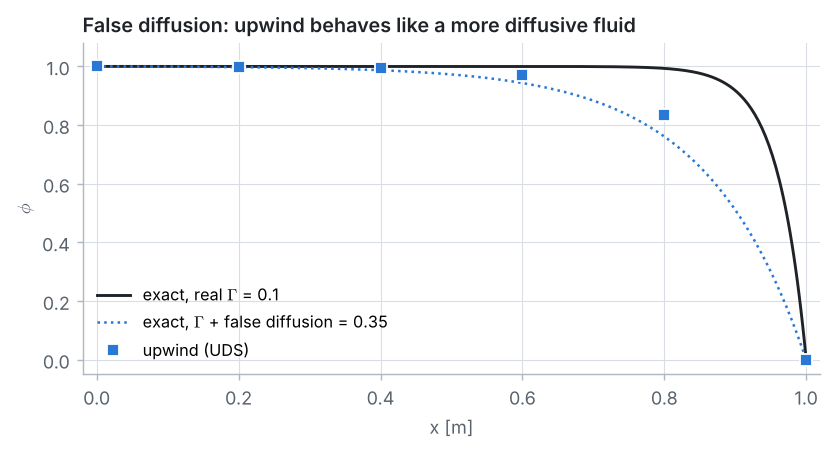

In [23]:
Gamma_uds = Gamma + rho * u_fast * dx / 2
plots.false_diffusion(x, phi_uds_fast, lambda xx: phi_exact(xx, u_fast),
                      lambda xx: phi_0 + (phi_L - phi_0) * (math.exp(rho * u_fast * xx / Gamma_uds) - 1)
                      / (math.exp(rho * u_fast * L / Gamma_uds) - 1), Gamma, Gamma_uds)

For the fast flow on our coarse grid, the false diffusion (0.25) is **2.5 times larger than the real diffusion** (0.1). The upwind points drop early, like the exact solution of a fluid with $\Gamma = 0.35$ (dotted), instead of staying near 1 like the real fluid with $\Gamma = 0.1$. They do not lie exactly on the dotted curve, because the upwind equations are the *central* equations for $\Gamma = 0.35$, which have their own discretization error. For the slow flow it is only 0.01, a tenth of the real one, which is why upwind did reasonably well in case 1.

### Verification: refining the grid

Both problems shrink with $\Delta x$: CDS becomes bounded once $Pe_\Delta < 2$, and the false diffusion $\rho u\,\Delta x/2$ goes to zero. Let us solve the fast flow on finer and finer grids and measure the **largest error** at the nodes. The **observed order** of accuracy between two grids is $p = \log(e_{coarse}/e_{fine})/\log 2$: we expect $p \to 2$ for CDS and $p \to 1$ for UDS.

In [24]:
grids = [5, 10, 20, 40, 80, 160, 320]
dxs, errors = [], {"CDS": [], "UDS": []}
print("    N    dx [m]     Pe     error CDS   order    error UDS   order")
for n_int in grids:
    line = f"{n_int:5d}  {L / n_int:8.6f}  {rho * u_fast * (L / n_int) / Gamma:5.3f}"
    for scheme in ("CDS", "UDS"):
        phi_n = solve(u_fast, n_int, scheme)
        error = max(abs(phi_n[i] - phi_exact(i * L / n_int, u_fast)) for i in range(n_int + 1))
        e = errors[scheme]
        order = f"{math.log(e[-1] / error) / math.log(2):5.2f}" if e else "     "
        e.append(error)
        line += f"   {error:9.6f}   {order}"
    dxs.append(L / n_int)
    print(line)

    N    dx [m]     Pe     error CDS   order    error UDS   order
    5  0.200000  5.000    0.414949            0.159822        
   10  0.100000  2.500    0.193196    1.10    0.203627   -0.35
   20  0.050000  1.250    0.055736    1.79    0.157940    0.37
   40  0.025000  0.625    0.012128    2.20    0.092193    0.78
   80  0.012500  0.312    0.003021    2.01    0.050679    0.86
  160  0.006250  0.156    0.000749    2.01    0.026983    0.91
  320  0.003125  0.078    0.000187    2.00    0.013922    0.95


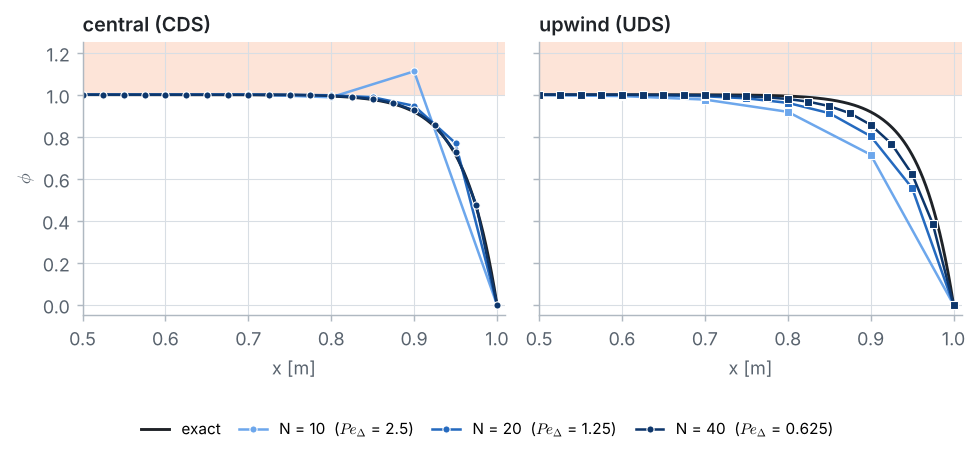

In [25]:
shown = (10, 20, 40)
plots.refined_profiles(L, {s: {n: solve(u_fast, n, s) for n in shown} for s in ("CDS", "UDS")},
                       lambda xx: phi_exact(xx, u_fast), {n: rho * u_fast * L / n / Gamma for n in shown})

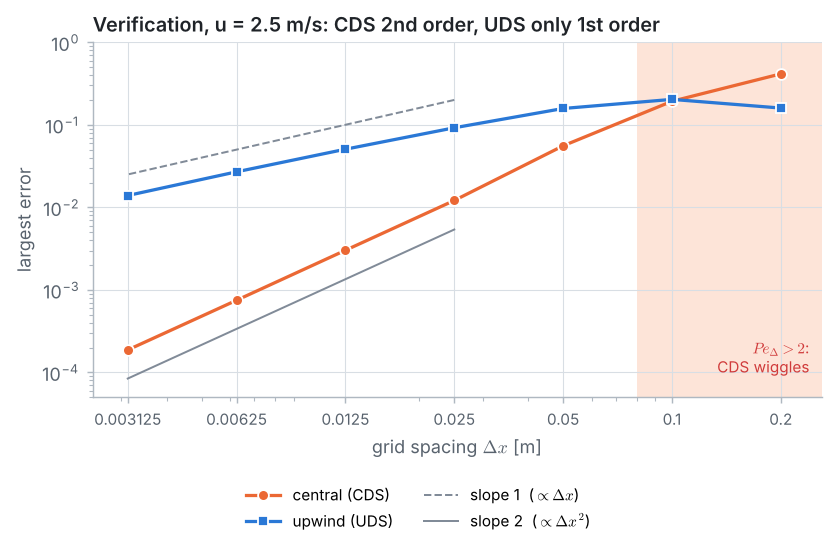

In [26]:
plots.convergence(dxs, errors, 2 * Gamma / (rho * u_fast))

The table tells the whole story:

* **CDS** is useless while $Pe_\Delta > 2$ ($N = 5$ and $10$; at $N = 10$ the error is still 0.19). Once $Pe_\Delta < 2$ it converges fast, and from $N = 40$ on the error falls by a factor of 4 per halving of $\Delta x$: **2nd order**.
* **UDS** never wiggles, but it converges slowly. Its error even *grows* from $N = 5$ to $N = 10$: on the coarsest grid no node lies inside the thin boundary layer, where the error is largest. On the finest grids the error only halves when $\Delta x$ is halved (the observed order creeps up to 0.95): **1st order**. With 320 intervals UDS (error 0.014) is still less accurate than CDS with 40 intervals (0.012), and CDS with 80 intervals is another four times better (0.003).

### Iterative solvers and diagonal dominance

Large 2D and 3D problems are solved by iteration, not by the Thomas algorithm. Gauss–Seidel (Problem 1) is **guaranteed** to converge when the matrix is diagonally dominant, but not otherwise. CDS at $Pe_\Delta > 2$ loses diagonal dominance, so let us test what happens, starting from $\phi = 0$ at every interior node:

In [27]:
def gauss_seidel(u, N, scheme, tol=1e-6, max_sweeps=200):
    """Gauss-Seidel sweeps for the interior nodes; returns the largest change of every sweep."""
    a_W, a_E, a_P = coefficients(u, N, scheme)
    phi = [phi_0] + [0.0] * (N - 1) + [phi_L]      # initial guess: 0 inside
    changes = []
    for sweep in range(max_sweeps):
        largest_change = 0.0
        for i in range(1, N):
            new_value = (a_W * phi[i - 1] + a_E * phi[i + 1]) / a_P
            largest_change = max(largest_change, abs(new_value - phi[i]))
            phi[i] = new_value                     # use the new value immediately
        changes.append(largest_change)
        if largest_change < tol or largest_change > 1e6:   # converged, or blown up
            break
    return changes


gs_runs = {}
for u, n_int, scheme in ((u_slow, 5, "CDS"), (u_fast, 5, "UDS"), (u_fast, 5, "CDS"), (u_fast, 10, "CDS")):
    changes = gauss_seidel(u, n_int, scheme)
    Pe = rho * u * (L / n_int) / Gamma
    verdict = "converged" if changes[-1] < 1e-6 else "DIVERGED"
    gs_runs[(scheme, Pe)] = changes
    print(f"{scheme}, Pe = {Pe:3.1f}, N = {n_int:2d}:  {verdict} after {len(changes):3d} sweeps "
          f"(last change {changes[-1]:.1e})")

CDS, Pe = 0.2, N =  5:  converged after  30 sweeps (last change 7.5e-07)
UDS, Pe = 5.0, N =  5:  converged after  13 sweeps (last change 8.7e-07)
CDS, Pe = 5.0, N =  5:  DIVERGED after  11 sweeps (last change 2.5e+06)
CDS, Pe = 2.5, N = 10:  converged after  26 sweeps (last change 8.7e-07)


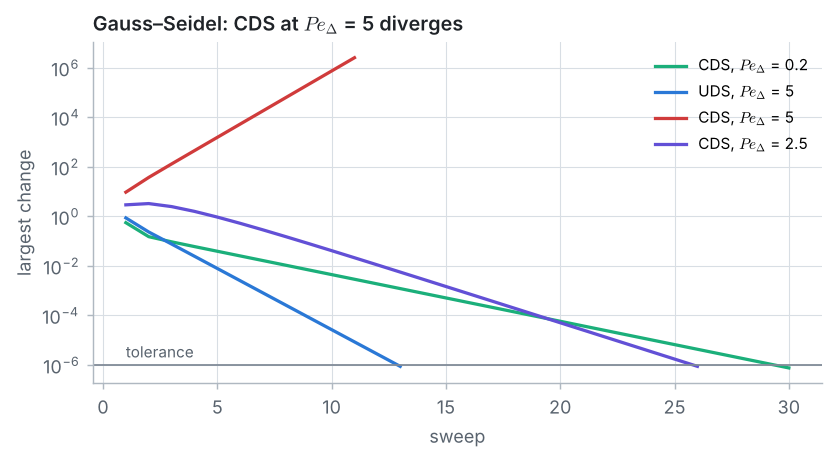

In [28]:
plots.gauss_seidel(gs_runs, 1e-6)

* With positive coefficients (CDS at $Pe_\Delta = 0.2$, UDS at $Pe_\Delta = 5$), Gauss–Seidel converges smoothly.
* CDS at $Pe_\Delta = 5$ **diverges**: every sweep makes the changes larger, and after only 11 sweeps a value changes by more than a million in one sweep.
* CDS at $Pe_\Delta = 2.5$ also lacks diagonal dominance, yet it converges. Losing diagonal dominance removes the *guarantee*, it does not always mean divergence. But a solver that may or may not converge is not something you want inside a commercial code.

### Why commercial CFD codes do not use plain central differences for convection

Real flows have huge Péclet numbers (for heat carried by air at 1 m/s over 1 m, $Pe$ is in the tens of thousands), so a grid fine enough to keep $Pe_\Delta < 2$ everywhere is usually far too expensive. Plain upwind is robust but too diffusive. Commercial codes therefore use **upwind-biased** schemes (second-order upwind, QUICK, TVD schemes with limiters) or add a carefully controlled amount of numerical diffusion only where it is needed (**stabilisation**). COMSOL, for example, applies streamline-diffusion stabilisation by default in its transport interfaces for exactly this reason.

---
## Summary

* The **convection term** $d(\rho u\phi)/dx$ carries $\phi$ with the flow, in one direction only; it is what turns a heat-conduction problem into a *fluid* problem.
* The **Péclet number** $Pe = \rho u L/\Gamma$ measures convection against diffusion; on a grid the **cell Péclet number** $Pe_\Delta = \rho u\,\Delta x/\Gamma$ decides how a scheme behaves.
* **Central differences** (2nd order) are accurate for $Pe_\Delta \le 2$, but for $Pe_\Delta > 2$ a neighbour coefficient becomes negative and the solution **wiggles** outside the physical bounds. For $Pe_\Delta = 5$ Gauss–Seidel even diverges.
* **Upwind differences** are always bounded and respect transportiveness, but they add **false diffusion** $\rho u\,\Delta x/2$ and are only 1st order.
* Refining the grid cures both, at a price: CDS converges at 2nd order once $Pe_\Delta < 2$, UDS at only 1st order.

## Try it yourself

1. Set `N = 10` in the grid cell and re-run. Which case wiggles now? Then try `N = 12` ($Pe_\Delta \approx 2.08$) and `N = 13` ($Pe_\Delta \approx 1.92$).
2. Reverse the flow, `u_fast = -2.5`. Which node is now "upwind"? Change `coefficients` so that UDS works for both signs of $u$ (hint: $a_W = D + \max(F, 0)$, $a_E = D + \max(-F, 0)$).
3. Find the velocity at which CDS on 5 intervals starts to wiggle. Check it against $Pe_\Delta = 2$.
4. Plot the UDS result on 40 intervals together with the exact solution for $\Gamma_{UDS} = \Gamma + \rho u\,\Delta x/2$. How close are they now?
5. *Challenge:* implement the **hybrid scheme** (central where $Pe_\Delta \le 2$, upwind with no physical diffusion where $Pe_\Delta > 2$: $a_W = \max(F,\, D + F/2,\, 0)$, $a_E = \max(-F,\, D - F/2,\, 0)$). Is it bounded? What is its error at $N = 5$ and $N = 20$?